# Search-01 : Espaces d'états et formalisation de problèmes (Rust)

**Navigation** : [<< Search-01 Python](Search-01-StateSpace.ipynb) | [Index](../README.md) | [Search-02 Uninformed Python >>](Search-02-Uninformed.ipynb)

## Objectifs d'apprentissage

À la fin de ce notebook, vous saurez :

1. Traduire le formalisme des espaces d'états — le 5-uplet (S, s0, A, T, G) — en un **trait Rust** générique
2. Mesurer la taille d'un espace d'états et comprendre l'explosion factorielle (en `u128`)
3. Résoudre un problème de plus court chemin avec l'organe natif **`petgraph`** (Dijkstra) et reconstruire l'itinéraire
4. Calculer une centralité d'intermédiarité (algorithme de Brandes) et la comparer au jumeau Python (`networkx`)
5. Reconnaître les idiomes du kernel **evcxr** : cellules autonomes, `:dep` en tête, types opaques dans un bloc

**Durée estimée** : ~25 min | **Prérequis** : [Search-01 Python](Search-01-StateSpace.ipynb) | **Lien** : Voir aussi [Search-01 C#](Search-01-StateSpace-CSharp.ipynb)

***

Ce carnet est le jumeau Rust de [Search-01 Python](Search-01-StateSpace.ipynb). La théorie complète (définition formelle, exemples fondateurs, pièges classiques) vit dans le jumeau Python ; ici, l'accent est mis sur la **traduction du formalisme en Rust** et sur les organes natifs de l'écosystème.

**Note de parité** : le jumeau C# travaille sur un graphe de France légèrement différent (13 villes, 41 arcs) ; les valeurs chiffrées du présent carnet sont celles du jumeau Python (11 villes, 14 arêtes).

## Table des matières

1. [L'organe : la bibliothèque standard et la crate petgraph](#1-lorgane-la-bibliotheque-standard-et-la-crate-petgraph)
2. [Le formalisme : un trait SearchProblem](#2-le-formalisme-un-trait-searchproblem)
3. [Le taquin : explosion factorielle](#3-le-taquin-explosion-factorielle)
4. [Le problème routier : Dijkstra et centralité](#4-le-probleme-routier-dijkstra-et-centralite)
5. [Exemples guidés : missionnaires-cannibales et labyrinthe](#5-exemples-guides-missionnaires-cannibales-et-labyrinthe)
6. [Exercices](#6-exercices)

## Références

- Russell & Norvig, *Artificial Intelligence: A Modern Approach* (4e éd.), chapitre 3 — la formalisation (S, s0, A, T, G)
- [Crate petgraph (crates.io)](https://crates.io/crates/petgraph) — graphes et algorithmes (MIT/Apache-2.0)
- [Crate plotters (crates.io)](https://crates.io/crates/plotters) — figures (MIT)
- [evcxr — le kernel Jupyter pour Rust](https://github.com/evcxr/evcxr)
- Brandes (2001), *A Faster Algorithm for Betweenness Centrality*

## 1. L'organe : la bibliothèque standard et la crate petgraph

Le jumeau Python écrit ses structures de données avec les `dict`/`set` de la bibliothèque standard et ses graphes avec `networkx`. En Rust, la bibliothèque standard fournit déjà les organes de base (`Vec`, `VecDeque`, `HashSet`, `HashMap`, `BinaryHeap`), et la crate **`petgraph`** est l'organe natif des graphes.

| | Jumeau Python | Ce carnet (Rust) |
|---|---|---|
| File FIFO du BFS | `collections.deque` | `std::collections::VecDeque` |
| Ensemble des états vus | `set` | `std::collections::HashSet` |
| Tas de priorité (Dijkstra) | `heapq` | `std::collections::BinaryHeap` (avec `Reverse`) |
| Graphe | classe maison + `networkx` | **crate `petgraph`** (l'organe) |
| Centralité | `networkx.betweenness_centrality` | algorithme de Brandes (copie pédagogique déclarée) |
| Figures | `matplotlib` | crate `plotters` (feature `evcxr`) |

Les deux `:dep` ci-dessous ajoutent les dépendances cargo **directement dans le kernel** — l'équivalent Rust des cellules `# pip install` (Python) ou `#r "nuget:"` (.NET). Ils sont en **tête du carnet uniquement** : un `:dep` ajouté plus bas recompile tout et efface les variables typées.

**Idiome evcxr suivi dans tout ce carnet** : les fonctions, traits et types d'une cellule ne sont pas fiablement persistés au-delà — chaque cellule de code est donc **autonome**, et son contenu est enclos dans un bloc `{ ... };` (le point-virgule final évite l'affichage parasite du `()`).

In [2]:
:dep petgraph = "0.7"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

## 2. Le formalisme : un trait SearchProblem

Un problème de recherche se définit par cinq composantes : l'ensemble des états `S`, l'état initial `s0`, les actions possibles `A(s)`, la transition `T(s, a)` et le test de but `G(s)`. En Python, c'est une classe abstraite ; en Rust, c'est un **trait** avec un **type associé** `State` — chaque problème choisit librement la représentation de ses états (une `struct`, un tableau `[u8; 9]`, un tuple...).

Le premier exemple est le **monde de l'aspirateur** à deux pièces : l'état dit où est l'aspirateur et quelles pièces sont sales.

```text
État = (position, pièce gauche sale ?, pièce droite sale ?)
```

In [3]:
// Chaque cellule de ce carnet est autonome : le kernel evcxr ne persiste pas
// fiablement les fonctions et les traits d'une cellule à l'autre. Tout ce dont
// la cellule a besoin est donc défini dans son propre bloc.
{
    // Le 5-uplet (S, s0, A, T, G) devient un trait : chaque problème de
    // recherche fournit ses cinq composantes, plus un coût unitaire par défaut.
    trait SearchProblem {
        type State: Clone + Eq + std::hash::Hash;
        fn initial_state(&self) -> Self::State;
        fn actions(&self, state: &Self::State) -> Vec<String>;
        fn transition(&self, state: &Self::State, action: &str) -> Self::State;
        fn is_goal(&self, state: &Self::State) -> bool;
        fn cost(&self, _state: &Self::State, _action: &str, _next: &Self::State) -> f64 { 1.0 }
    }

    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct VacuumState {
        position: char,       // 'G' ou 'D'
        gauche_sale: bool,
        droite_sale: bool,
    }

    struct VacuumWorld;

    impl SearchProblem for VacuumWorld {
        type State = VacuumState;
        fn initial_state(&self) -> VacuumState {
            VacuumState { position: 'G', gauche_sale: true, droite_sale: true }
        }
        fn actions(&self, s: &VacuumState) -> Vec<String> {
            let mut act = Vec::new();
            if s.position == 'G' && s.gauche_sale { act.push("Aspirer".to_string()); }
            if s.position == 'D' && s.droite_sale { act.push("Aspirer".to_string()); }
            if s.position == 'G' { act.push("Droite".to_string()); }
            else { act.push("Gauche".to_string()); }
            act
        }
        fn transition(&self, s: &VacuumState, action: &str) -> VacuumState {
            let mut n = s.clone();
            match action {
                "Aspirer" => { if n.position == 'G' { n.gauche_sale = false; } else { n.droite_sale = false; } }
                "Droite" => { n.position = 'D'; }
                "Gauche" => { n.position = 'G'; }
                _ => {}
            }
            n
        }
        fn is_goal(&self, s: &VacuumState) -> bool { !s.gauche_sale && !s.droite_sale }
    }

    let monde = VacuumWorld;
    let s0 = monde.initial_state();
    println!("Etat initial      : {:?}", s0);
    println!("Actions possibles : {:?}", monde.actions(&s0));
    println!("Est-ce le but ?   : {}", monde.is_goal(&s0));
    println!("Taille de l'espace d'etats : 8 (2 positions x 2 etats G x 2 etats D)");
};

Etat initial      : VacuumState { position: 'G', gauche_sale: true, droite_sale: true }


Actions possibles : ["Aspirer", "Droite"]


Est-ce le but ?   : false


Taille de l'espace d'etats : 8 (2 positions x 2 etats G x 2 etats D)


### Lecture du résultat

L'état initial place l'aspirateur à **Gauche**, les deux pièces sales : `VacuumState { position: 'G', gauche_sale: true, droite_sale: true }`. Deux actions y sont possibles — **Aspirer** (la pièce gauche est sale et l'aspirateur y est) et **Droite** — exactement les deux branches qui partent de la racine du graphe d'états du jumeau Python. L'espace d'états compte 8 états : 2 positions de l'aspirateur fois 2 fois 2 états de saleté. Le but — les deux pièces propres — n'est pas encore atteint.

In [4]:
{
    // (Rédéfinition locale : chaque cellule est autonome, voir cellule précédente.)
    trait SearchProblem {
        type State: Clone + Eq + std::hash::Hash;
        fn initial_state(&self) -> Self::State;
        fn actions(&self, state: &Self::State) -> Vec<String>;
        fn transition(&self, state: &Self::State, action: &str) -> Self::State;
        fn is_goal(&self, state: &Self::State) -> bool;
        fn cost(&self, _state: &Self::State, _action: &str, _next: &Self::State) -> f64 { 1.0 }
    }

    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct VacuumState {
        position: char,
        gauche_sale: bool,
        droite_sale: bool,
    }

    struct VacuumWorld;

    impl SearchProblem for VacuumWorld {
        type State = VacuumState;
        fn initial_state(&self) -> VacuumState {
            VacuumState { position: 'G', gauche_sale: true, droite_sale: true }
        }
        fn actions(&self, s: &VacuumState) -> Vec<String> {
            let mut act = Vec::new();
            if s.position == 'G' && s.gauche_sale { act.push("Aspirer".to_string()); }
            if s.position == 'D' && s.droite_sale { act.push("Aspirer".to_string()); }
            if s.position == 'G' { act.push("Droite".to_string()); }
            else { act.push("Gauche".to_string()); }
            act
        }
        fn transition(&self, s: &VacuumState, action: &str) -> VacuumState {
            let mut n = s.clone();
            match action {
                "Aspirer" => { if n.position == 'G' { n.gauche_sale = false; } else { n.droite_sale = false; } }
                "Droite" => { n.position = 'D'; }
                "Gauche" => { n.position = 'G'; }
                _ => {}
            }
            n
        }
        fn is_goal(&self, s: &VacuumState) -> bool { !s.gauche_sale && !s.droite_sale }
    }

    // BFS générique sur n'importe quel SearchProblem : file FIFO de couples
    // (état, chemin), ensemble HashSet des états déjà enfilés.
    use std::collections::{HashSet, VecDeque};
    fn bfs_resoudre<P: SearchProblem>(pb: &P) -> Option<(Vec<String>, P::State)> {
        let init = pb.initial_state();
        if pb.is_goal(&init) { return Some((Vec::new(), init)); }
        let mut vus: HashSet<P::State> = HashSet::new();
        let mut file: VecDeque<(P::State, Vec<String>)> = VecDeque::new();
        vus.insert(init.clone());
        file.push_back((init, Vec::new()));
        while let Some((etat, chemin)) = file.pop_front() {
            for a in pb.actions(&etat) {
                let suivant = pb.transition(&etat, &a);
                if pb.is_goal(&suivant) {
                    let mut c = chemin.clone();
                    c.push(a);
                    return Some((c, suivant));
                }
                if vus.insert(suivant.clone()) {
                    let mut c = chemin.clone();
                    c.push(a);
                    file.push_back((suivant, c));
                }
            }
        }
        None
    }

    let monde = VacuumWorld;
    let (chemin, _but) = bfs_resoudre(&monde).unwrap();

    // Trace pas à pas de la solution optimale
    let mut etat = monde.initial_state();
    let mut cout = 0.0;
    println!("{:<6}{:<9}{:<24}{}", "Etape", "Action", "Etat (pos, G, D)", "But ?");
    let g = if etat.gauche_sale { "sale" } else { "propre" };
    let d = if etat.droite_sale { "sale" } else { "propre" };
    println!("{:<6}{:<9}{:<24}{}", 0, "-", format!("({}, {}, {})", etat.position, g, d), monde.is_goal(&etat));
    for (i, a) in chemin.iter().enumerate() {
        let avant = etat.clone();
        etat = monde.transition(&etat, a);
        cout += monde.cost(&avant, a, &etat);
        let g = if etat.gauche_sale { "sale" } else { "propre" };
        let d = if etat.droite_sale { "sale" } else { "propre" };
        println!("{:<6}{:<9}{:<24}{}", i + 1, a, format!("({}, {}, {})", etat.position, g, d), monde.is_goal(&etat));
    }
    println!();
    println!("Solution optimale en {} etapes, cout total : {}", chemin.len(), cout);
};

Etape Action   Etat (pos, G, D)        But ?


0     -        (G, sale, sale)         false


1     Aspirer  (G, propre, sale)       false


2     Droite   (D, propre, sale)       false


3     Aspirer  (D, propre, propre)     true


Solution optimale en 3 etapes, cout total : 3


### Lecture du résultat

La file FIFO du BFS garantit que la première solution rencontrée est la **plus courte** : trois étapes, de coût total `3` (chaque action coûte 1). La séquence **Aspirer -> Droite -> Aspirer** n'aspire chaque pièce qu'une fois et ne fait qu'un seul déplacement — une solution qui commencerait par `Droite` coûterait au moins une étape de plus (il faudrait revenir à gauche). C'est le même résultat que le jumeau Python : la réponse du problème ne dépend pas du langage, seule son écriture change.

### Le graphe d'états complet

Les 8 états forment un petit graphe. Pour chaque état initial possible, la distance au but se calcule par le même BFS — c'est exactement ce que fait un solveur non informé (détail au [Search-02](Search-02-Uninformed.ipynb)) : partir d'un état et compter les arcs jusqu'au but.

In [5]:
{
    trait SearchProblem {
        type State: Clone + Eq + std::hash::Hash;
        fn initial_state(&self) -> Self::State;
        fn actions(&self, state: &Self::State) -> Vec<String>;
        fn transition(&self, state: &Self::State, action: &str) -> Self::State;
        fn is_goal(&self, state: &Self::State) -> bool;
    }

    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct VacuumState {
        position: char,
        gauche_sale: bool,
        droite_sale: bool,
    }

    // Variante paramétrée par son état de départ : sert à mesurer la distance
    // au but depuis CHACUN des 8 états de l'espace.
    struct VacuumWorld { depart: VacuumState }

    impl SearchProblem for VacuumWorld {
        type State = VacuumState;
        fn initial_state(&self) -> VacuumState { self.depart.clone() }
        fn actions(&self, s: &VacuumState) -> Vec<String> {
            let mut act = Vec::new();
            if s.position == 'G' && s.gauche_sale { act.push("Aspirer".to_string()); }
            if s.position == 'D' && s.droite_sale { act.push("Aspirer".to_string()); }
            if s.position == 'G' { act.push("Droite".to_string()); }
            else { act.push("Gauche".to_string()); }
            act
        }
        fn transition(&self, s: &VacuumState, action: &str) -> VacuumState {
            let mut n = s.clone();
            match action {
                "Aspirer" => { if n.position == 'G' { n.gauche_sale = false; } else { n.droite_sale = false; } }
                "Droite" => { n.position = 'D'; }
                "Gauche" => { n.position = 'G'; }
                _ => {}
            }
            n
        }
        fn is_goal(&self, s: &VacuumState) -> bool { !s.gauche_sale && !s.droite_sale }
    }

    use std::collections::{HashSet, VecDeque};
    fn distance_au_but<P: SearchProblem>(pb: &P) -> Option<usize> {
        let init = pb.initial_state();
        if pb.is_goal(&init) { return Some(0); }
        let mut vus: HashSet<P::State> = HashSet::new();
        let mut file: VecDeque<P::State> = VecDeque::new();
        vus.insert(init.clone());
        file.push_back(init);
        let mut profondeur: std::collections::HashMap<P::State, usize> = std::collections::HashMap::new();
        profondeur.insert(pb.initial_state(), 0);
        while let Some(etat) = file.pop_front() {
            let d = profondeur[&etat];
            for a in pb.actions(&etat) {
                let suivant = pb.transition(&etat, &a);
                if pb.is_goal(&suivant) { return Some(d + 1); }
                if vus.insert(suivant.clone()) {
                    profondeur.insert(suivant.clone(), d + 1);
                    file.push_back(suivant);
                }
            }
        }
        None
    }

    fn affiche(s: &VacuumState) -> String {
        let g = if s.gauche_sale { "sale" } else { "propre" };
        let d = if s.droite_sale { "sale" } else { "propre" };
        format!("({}, {}, {})", s.position, g, d)
    }

    println!("{:<24}{:<32}{}", "Etat", "Actions possibles", "Distance au but");
    for position in ['G', 'D'] {
        for gauche in [true, false] {
            for droite in [true, false] {
                let depart = VacuumState { position, gauche_sale: gauche, droite_sale: droite };
                let monde = VacuumWorld { depart: depart.clone() };
                let d = distance_au_but(&monde).unwrap();
                println!("{:<24}{:<32}{}", affiche(&depart), format!("{:?}", monde.actions(&depart)), d);
            }
        }
    }
};

Etat                    Actions possibles               Distance au but


(G, sale, sale)         ["Aspirer", "Droite"]           3


(G, sale, propre)       ["Aspirer", "Droite"]           1


(G, propre, sale)       ["Droite"]                      2


(G, propre, propre)     ["Droite"]                      0


(D, sale, sale)         ["Aspirer", "Gauche"]           3


(D, sale, propre)       ["Gauche"]                      2


(D, propre, sale)       ["Aspirer", "Gauche"]           1


(D, propre, propre)     ["Gauche"]                      0


### Lecture du résultat

La colonne de droite dessine le relief de l'espace d'états : l'état but `(D, propre, propre)` (et son jumeau `(G, propre, propre)`) est à distance 0, les états où une seule pièce reste sale à distance 1 ou 2 selon la position de l'aspirateur, et l'état initial `(G, sale, sale)` tout en haut à distance 3. Aucun état n'est à plus de 3 actions du but : sur un espace de 8 états, le BFS explore tout quasi instantanément — la difficulté des problèmes combinatoires vient de la **taille** de l'espace, pas de la complexité de chaque étape. C'est ce que montre la section suivante.

## 3. Le taquin : explosion factorielle

Le **taquin 3x3** (8-puzzle) est l'exemple classique d'espace d'états énorme malgré des règles minuscules. L'état est un tableau `[u8; 9]` des chiffres 1 à 8 plus 0 pour la case vide ; le but est `1 2 3 / 4 5 6 / 7 8 -`.

In [6]:
{
    let initial: [u8; 9] = [7, 2, 4, 5, 0, 6, 8, 3, 1];
    let but: [u8; 9] = [1, 2, 3, 4, 5, 6, 7, 8, 0];

    // Actions possibles selon la position de la case vide : la case vide peut
    // monter, descendre, aller a gauche ou a droite si elle reste dans la grille.
    fn voisins_case_vide(pos: usize) -> Vec<(&'static str, usize)> {
        let (l, c) = (pos / 3, pos % 3);
        let mut v = Vec::new();
        if l > 0 { v.push(("Haut", pos - 3)); }
        if l < 2 { v.push(("Bas", pos + 3)); }
        if c > 0 { v.push(("Gauche", pos - 1)); }
        if c < 2 { v.push(("Droite", pos + 1)); }
        v
    }

    fn appliquer(etat: &[u8; 9], action: &str) -> [u8; 9] {
        let vide = etat.iter().position(|&x| x == 0).unwrap();
        let voisins = voisins_case_vide(vide);
        let cible = voisins.iter().find(|(a, _)| *a == action).map(|(_, t)| *t).unwrap();
        let mut n = *etat;
        n[vide] = n[cible];
        n[cible] = 0;
        n
    }

    let vide = initial.iter().position(|&x| x == 0).unwrap();
    let voisins = voisins_case_vide(vide);
    let actions: Vec<&str> = voisins.iter().map(|(a, _)| *a).collect();
    println!("Etat initial  : {:?}", initial);
    println!("But           : {:?}", but);
    println!("Case vide en position {} (ligne {}, colonne {}) -> {} voisins", vide, vide / 3, vide % 3, voisins.len());
    println!("Actions depuis l'etat initial : {:?}", actions);
    println!("Apres 'Haut'  : {:?}", appliquer(&initial, "Haut"));
    println!();

    let mut factorielle: u64 = 1;
    for i in 2..=9u64 { factorielle *= i; }
    println!("Permutations possibles : 9! = {}", factorielle);
    println!("Etats accessibles (invariant de parite) : {}", factorielle / 2);
    println!();

    let total: usize = (0..9).map(|p| voisins_case_vide(p).len()).sum();
    println!("Facteur de branchement selon la position de la case vide :");
    println!("  Coin (positions 0, 2, 6, 8)  : 2 actions");
    println!("  Bord (positions 1, 3, 5, 7)  : 3 actions");
    println!("  Centre (position 4)          : 4 actions");
    println!("  Facteur de branchement moyen : {:.2}", total as f64 / 9.0);
};

Etat initial  : [7, 2, 4, 5, 0, 6, 8, 3, 1]


But           : [1, 2, 3, 4, 5, 6, 7, 8, 0]


Case vide en position 4 (ligne 1, colonne 1) -> 4 voisins


Actions depuis l'etat initial : ["Haut", "Bas", "Gauche", "Droite"]


Apres 'Haut'  : [7, 0, 4, 5, 2, 6, 8, 3, 1]


Permutations possibles : 9! = 362880


... (2 outputs left out)

  Coin (positions 0, 2, 6, 8)  : 2 actions


  Bord (positions 1, 3, 5, 7)  : 3 actions


  Centre (position 4)          : 4 actions


  Facteur de branchement moyen : 2.67


### Lecture du résultat

La case vide est au **centre** (position 4) : 4 actions y sont possibles — `Haut`, `Bas`, `Gauche`, `Droite` (dans cet ordre de test). L'espace compte `9! = 362880` permutations, mais seule la **moitié** est accessible depuis un état donné : l'invariant de parité (le nombre d'inversions) scinde les permutations en deux classes. Le facteur de branchement moyen est `(4x2 + 4x3 + 1x4) / 9 = 2.67` — c'est lui, combiné à la profondeur des solutions (plus de 20 coups pour le pire état du 8-puzzle), qui rend l'espace effectivement exploré si volumineux.

### La taille de l'espace selon le taquin

Passons le taquin à l'échelle : 3-puzzle (2x2), 8-puzzle (3x3), 15-puzzle (4x4), 24-puzzle (5x5). La taille de l'espace est factorielle en le nombre de cases — et un ordinateur qui énumère `1e9` états par seconde reste sidéré.

**Le piège des entiers** : en Rust, le factoriel de 21 dépasse `u64` — un débordement arithmétique **panique en debug** (`attempt to multiply with overflow`) au lieu de s'enrouler en silence comme en C. La cellule utilise donc `u128`, qui représente jusqu'à environ `3.4e38` : `25!` (environ `1.55e25`) y tient largement.

In [7]:
{
    fn factorielle(n: u32) -> u128 {
        (2..=n as u128).product()
    }

    fn sep(n: u128) -> String {
        let s = n.to_string();
        let octets = s.as_bytes();
        let mut out = String::new();
        for (i, b) in octets.iter().enumerate() {
            if i > 0 && (octets.len() - i) % 3 == 0 { out.push(','); }
            out.push(*b as char);
        }
        out
    }

    fn format_duree(nb_etats: u128) -> String {
        let secondes = nb_etats as f64 / 1e9;
        if secondes < 1e-6 { format!("{:.0} ns", secondes * 1e9) }
        else if secondes < 1e-3 { format!("{:.1} us", secondes * 1e6) }
        else if secondes < 1.0 { format!("{:.2} ms", secondes * 1e3) }
        else if secondes < 86400.0 { format!("{:.1} h", secondes / 3600.0) }
        else { format!("{:.2e} ans", secondes / 3.156e7) }
    }

    assert_eq!(factorielle(0), 1);
    assert_eq!(factorielle(5), 120);
    assert_eq!(factorielle(9) / 2, 181_440);
    assert_eq!(factorielle(16) / 2, 10_461_394_944_000);
    assert_eq!(factorielle(25), 15_511_210_043_330_985_984_000_000u128);

    println!("{:<11}{:>4}  {:>26}  {:>26}  {:>10}", "Puzzle", "cases", "Permutations", "Accessibles", "Durée");
    // La factorielle porte sur les cases (tuiles + case vide) : 4, 9, 16, 25.
    for (nom, cases) in [("3-puzzle", 4u32), ("8-puzzle", 9), ("15-puzzle", 16), ("24-puzzle", 25)] {
        let total = factorielle(cases);
        let accessibles = total / 2;
        println!("{:<11}{:>4}  {:>26}  {:>26}  {:>10}", nom, cases, sep(total), sep(accessibles), format_duree(accessibles));
    }
};

Puzzle     cases                Permutations                 Accessibles       Durée


3-puzzle      4                          24                          12       12 ns


8-puzzle      9                     362,880                     181,440    181.4 us


15-puzzle    16          20,922,789,888,000          10,461,394,944,000       2.9 h


24-puzzle    25  15,511,210,043,330,985,984,000,000  7,755,605,021,665,492,992,000,000  2.46e8 ans


### Lecture du tableau

Le nombre d'états accessibles croît en **multiplication**, pas en addition : d'une ligne à la suivante, il est multiplié par plus de `10^4`, puis `10^7`, puis `10^11`. À un milliard d'états par seconde, l'énumération exhaustive passe de `181.4 us` (8-puzzle) à `2.9 h` (15-puzzle), puis à `2.46e8 ans` (24-puzzle) — environ 800 fois l'âge de notre espèce. Le 15-puzzle marque la limite pratique de l'énumération exhaustive ; au-delà, il faut des **heuristiques** (recherche A*, au [Search-03](Search-03-Informed.ipynb)) pour n'explorer qu'une infime partie de cet espace. C'est la leçon structurante de la série Search.

La figure suivante trace `log10` du nombre d'états accessibles contre le nombre `k` de tuiles numérotées (3, 8, 15, 24). La case vide compte aussi : il y a `(k+1)!` arrangements et la moitié est accessible depuis une configuration donnée. L'échelle logarithmique permet de comparer ces espaces de tailles très différentes.

k =  3 tuiles : log10(états accessibles) = 1.08


k =  8 tuiles : log10(états accessibles) = 5.26


k = 15 tuiles : log10(états accessibles) = 13.02


k = 24 tuiles : log10(états accessibles) = 24.89


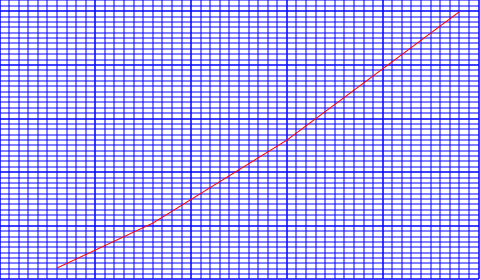

In [8]:
use plotters::prelude::*;

// Figure : log10((k+1)!/2), avec k tuiles et une case vide.
{
    fn log10_accessibles(k: u32) -> f64 {
        let mut r: u128 = 1;
        for i in 2..=((k + 1) as u128) { r *= i; }
        ((r / 2) as f64).log10()
    }
    let data: Vec<(f64, f64)> = [3u32, 8, 15, 24].iter()
        .map(|&k| (k as f64, log10_accessibles(k))).collect();
    for &(k, y) in &data {
        println!("k = {:>2} tuiles : log10(états accessibles) = {:.2}", k, y);
    }
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (480, 280)).into_drawing_area();
        let mut chart = ChartBuilder::on(&root)
            .build_cartesian_2d(0f64..25f64, 0f64..26f64)?;
        chart.configure_mesh().bold_line_style(BLUE).light_line_style(BLUE).draw()?;
        chart.draw_series(LineSeries::new(data.clone(), RED))?;
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
};

### Lecture de la figure

Axe horizontal : taille `k` du taquin (3 à 24). Axe vertical : `log10` du nombre d'états accessibles (0 à 25). La courbe monte de `log10(12) = 1.08` pour le 3-puzzle à `log10(7.76e24) = 24.89` pour le 24-puzzle : **près de 24 ordres de grandeur en 4 points**. En échelle linéaire, la même série serait verticale dès le troisième point — c'est précisément pourquoi les manuels la tracent en log : seule l'échelle logarithmique laisse les petits taquins visibles à côté des grands.

## 4. Le problème routier : Dijkstra et centralité

Deuxième famille d'exemples : le **problème de recherche de trajet**. L'état est la ville courante, les actions sont les routes entrantes/sortantes, la transition change de ville, le test de but est la ville d'arrivée, et — nouveauté — le **coût** d'une action est la longueur en kilomètres de la route.

> **Note de parité** : le jumeau C# résout le même problème sur un graphe différent (13 villes, 41 arcs) ; les valeurs ci-dessous sont celles du jumeau Python : **11 villes, 14 arêtes symétriques** (28 arcs orientation confondue).

In [9]:
// Graphe routier de France : 11 villes, 14 arêtes symétriques.
// Ce `let` de données simples persiste d'une cellule à l'autre (evcxr garde
// les variables top-level de types simples) ; les fonctions, elles, ne
// persistent pas fiablement — les cellules suivantes restent autonomes.
let france_edges: Vec<(&'static str, &'static str, u32)> = vec![
    ("Paris", "Lyon", 465),
    ("Paris", "Lille", 225),
    ("Paris", "Strasbourg", 490),
    ("Paris", "Nantes", 385),
    ("Paris", "Bordeaux", 585),
    ("Lyon", "Marseille", 315),
    ("Lyon", "Grenoble", 105),
    ("Lyon", "Strasbourg", 490),
    ("Lille", "Strasbourg", 525),
    ("Bordeaux", "Toulouse", 245),
    ("Bordeaux", "Nantes", 345),
    ("Toulouse", "Montpellier", 245),
    ("Montpellier", "Marseille", 170),
    ("Marseille", "Nice", 200),
];
{
    use std::collections::HashMap;

    // Adjacence : chaque arête donne deux arcs (graphe non orienté).
    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    let mut villes: Vec<&str> = Vec::new();
    for (a, b, _) in &france_edges {
        if !villes.contains(a) { villes.push(a); }
        if !villes.contains(b) { villes.push(b); }
    }
    let arcs: usize = adj.values().map(|v| v.len()).sum();
    println!("Villes : {}", villes.len());
    println!("Arcs (aretes x 2) : {}", arcs);
    println!("Facteur de branchement : {:.2}", arcs as f64 / villes.len() as f64);
    println!();
    println!("Voisins de Bordeaux : {:?}", adj["Bordeaux"]);
    println!("Voisins de Paris    : {:?}", adj["Paris"]);
};

Villes : 11


Arcs (aretes x 2) : 28


Facteur de branchement : 2.55


Voisins de Bordeaux : [("Paris", 585), ("Toulouse", 245), ("Nantes", 345)]


Voisins de Paris    : [("Lyon", 465), ("Lille", 225), ("Strasbourg", 490), ("Nantes", 385), ("Bordeaux", 585)]


### Lecture du résultat

L'adjacence se construit en une passe : chaque arête est ajoutée **deux fois** dans la `HashMap` (une par sens de parcours), d'où 28 arcs pour 14 arêtes. Le facteur de branchement du graphe routier est `28 / 11 = 2.55` — comparable au 2.67 du taquin, mais l'espace est minuscule (11 états) : la difficulté des graphes routiers vient de la **structure des coûts**, pas du cardinal.

In [10]:
{
    // graphe d'adjacence : ville -> liste de (voisin, distance en km)
    use std::collections::HashMap;
    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        // chaque route relie ses deux extrémités (graphe non dirigé)
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    // distance d'un arc direct entre a et b
    fn distance_directe(adj: &HashMap<&str, Vec<(&str, u32)>>, a: &str, b: &str) -> u32 {
        adj[a].iter().find(|(v, _)| *v == b).map(|(_, d)| *d).unwrap()
    }
    // longueur d'un chemin = somme des distances de ses arcs consecutifs
    fn longueur(adj: &HashMap<&str, Vec<(&str, u32)>>, chemin: &[&str]) -> u32 {
        chemin.windows(2).map(|p| distance_directe(adj, p[0], p[1])).sum()
    }

    // deux itinéraires de Bordeaux à Strasbourg : via Paris (court) vs via le sud (long)
    let via_paris = ["Bordeaux", "Paris", "Strasbourg"];
    let via_sud = ["Bordeaux", "Toulouse", "Montpellier", "Marseille", "Lyon", "Strasbourg"];
    let d1 = longueur(&adj, &via_paris);
    let d2 = longueur(&adj, &via_sud);
    println!("Chemin 1 (via Paris) : {} etapes", via_paris.len() - 1);
    println!("  {}", via_paris.join(" -> "));
    println!("  Distance totale : {} km", d1);
    println!();
    println!("Chemin 2 (via le sud) : {} etapes", via_sud.len() - 1);
    println!("  {}", via_sud.join(" -> "));
    println!("  Distance totale : {} km", d2);
    println!();
    println!("Ecart : {} km en faveur du chemin via Paris ({} etapes contre {})",
        d2 - d1, via_paris.len() - 1, via_sud.len() - 1);
};

Chemin 1 (via Paris) : 2 etapes


  Bordeaux -> Paris -> Strasbourg


  Distance totale : 1075 km


Chemin 2 (via le sud) : 5 etapes


  Bordeaux -> Toulouse -> Montpellier -> Marseille -> Lyon -> Strasbourg


  Distance totale : 1465 km


Ecart : 390 km en faveur du chemin via Paris (2 etapes contre 5)


### Lecture du résultat

Les deux itinéraires relient Bordeaux à Strasbourg, mais le parallèle s'arrête là : **via Paris, 2 étapes et 1075 km ; via le sud, 5 étapes et 1465 km** — un écart de 390 km. Moins d'étapes et moins de kilomètres ne sont pas automatiquement liés (sur certains réseaux, le détour par un hub allonge le compte d'étapes mais raccourcit la distance) ; ici les deux critères préfèrent le même chemin. Le BFS du monde de l'aspirateur optimisait le **nombre d'actions** ; pour optimiser la **distance**, il faut un algorithme sensible aux coûts — c'est le rôle de Dijkstra.

### L'organe natif : `petgraph::algo::dijkstra`

Le réflexe Rust n'est pas de réimplémenter Dijkstra : la crate `petgraph` fournit le graphe (`Graph`) et l'algorithme (`petgraph::algo::dijkstra`). La fonction renvoie la distance minimale de la source à **chaque** sommet — pas le chemin lui-même : l'itinéraire se reconstruit en remontant depuis l'arrivée, sommet par sommet, en cherchant le voisin `v` tel que `dist(v) + poids(v -> courant) = dist(courant)`.

In [11]:
{
    use petgraph::Graph;
    use petgraph::Undirected;
    use petgraph::algo::dijkstra;
    use std::collections::HashMap;

    let mut g: Graph<&str, u32, Undirected> = Graph::new_undirected();
    let mut idx: HashMap<&str, petgraph::graph::NodeIndex> = HashMap::new();
    let mut villes: Vec<&str> = Vec::new();
    for (a, b, _) in &france_edges {
        if !villes.contains(a) { villes.push(a); }
        if !villes.contains(b) { villes.push(b); }
    }
    for v in &villes { idx.insert(v, g.add_node(v)); }
    for (a, b, d) in &france_edges { g.add_edge(idx[a], idx[b], *d); }

    let depart = idx["Bordeaux"];
    let arrivee = idx["Strasbourg"];
    let dists = dijkstra(&g, depart, None, |e| *e.weight());

    // Reconstruction de l'itinéraire : depuis l'arrivée, remonter vers un
    // voisin v tel que dist(v) + poids(v, courant) = dist(courant).
    let mut chemin: Vec<&str> = vec!["Strasbourg"];
    let mut courant = arrivee;
    while courant != depart {
        for voisin in g.neighbors(courant) {
            if let Some(e) = g.find_edge(voisin, courant) {
                let w = *g.edge_weight(e).unwrap();
                if dists[&voisin] + w == dists[&courant] {
                    chemin.push(g[voisin]);
                    courant = voisin;
                    break;
                }
            }
        }
    }
    chemin.reverse();

    println!("Plus courte distance Bordeaux -> Strasbourg : {} km", dists[&arrivee]);
    println!("Itineraire : {}", chemin.join(" -> "));
    println!("Verification : {} sommets, {} aretes, facteur de branchement {:.2}",
        g.node_count(), g.edge_count(), g.edge_count() as f64 / g.node_count() as f64);
};

Plus courte distance Bordeaux -> Strasbourg : 1075 km


Itineraire : Bordeaux -> Paris -> Strasbourg


Verification : 11 sommets, 14 aretes, facteur de branchement 1.27


### Lecture du résultat

L'organe confirme le calcul manuel : **1075 km** par l'itinéraire `Bordeaux -> Paris -> Strasbourg` — la même réponse que la cellule précédente, obtenue cette fois par un algorithme qui n'a jamais vu les deux candidats à la main : Dijkstra a étendu sa frontière depuis Bordeaux et provoque l'arrivée par le chemin le moins cher. C'est le modèle de la **vérification croisée** : le chemin construit à la main (cellule précédente) et le chemin calculé par l'organe (cette cellule) se recoupent, et la reconstruction par remontée des distances est la partie qui, en pratique, se bugge le plus — la boucle `while` ci-dessus en est l'implémentation minimale.

### Centralité d'intermédiarité (betweenness)

Quelles villes portent le réseau ? La **centralité d'intermédiarité** d'une ville est la proportion de plus courts chemins (entre toutes les paires d'autres villes) qui passent par elle. Le jumeau Python appelle `networkx.betweenness_centrality` ; `petgraph` ne fournit **pas** cette mesure.

**Copie pédagogique déclarée** (règle organ-first) : l'algorithme de Brandes (2001) est implanté ici en une trentaine de lignes — un Dijkstra par source qui compte les plus courts chemins (`sigma`), mémorise les prédécesseurs, puis rétro-propage les dépendances. Motif : voir comment la mesure se calcule ; l'organe Python reste la référence du chiffre. La normalisation divise par `(n-1)(n-2) = 90` pour 11 villes (paires ordonnées).

In [12]:
{
    use std::cmp::Reverse;
    use std::collections::{BinaryHeap, HashMap, HashSet};

    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    let mut villes: Vec<&str> = Vec::new();
    for (a, b, _) in &france_edges {
        if !villes.contains(a) { villes.push(a); }
        if !villes.contains(b) { villes.push(b); }
    }
    let n = villes.len();

    // Copie pedagogique declaree : Brandes (2001) sur graphe non oriente value.
    let mut cb: HashMap<&str, f64> = villes.iter().map(|v| (*v, 0.0)).collect();

    for &s in &villes {
        // Dijkstra depuis s : distances, nombre de plus courts chemins (sigma),
        // predecesseurs, ordre de finalisation (pour la retro-propagation).
        let mut dist: HashMap<&str, u32> = HashMap::new();
        let mut sigma: HashMap<&str, u64> = villes.iter().map(|v| (*v, 0)).collect();
        let mut preds: HashMap<&str, Vec<&str>> = HashMap::new();
        let mut ordre: Vec<&str> = Vec::new();
        let mut finis: HashSet<&str> = HashSet::new();
        let mut tas: BinaryHeap<Reverse<(u32, &str)>> = BinaryHeap::new();
        dist.insert(s, 0);
        *sigma.get_mut(&s).unwrap() = 1;
        tas.push(Reverse((0, s)));
        while let Some(Reverse((d, v))) = tas.pop() {
            if d > dist[v] { continue; }         // entree perimee du tas
            if !finis.insert(v) { continue; }     // sommet deja finalise
            ordre.push(v);
            for &(w, poids) in &adj[v] {
                let nouveau = d + poids;
                let dw = *dist.get(w).unwrap_or(&u32::MAX);
                if nouveau < dw {
                    dist.insert(w, nouveau);
                    *sigma.get_mut(&w).unwrap() = sigma[&v];
                    preds.insert(w, vec![v]);
                    tas.push(Reverse((nouveau, w)));
                } else if nouveau == dw {
                    *sigma.get_mut(&w).unwrap() += sigma[&v];
                    preds.get_mut(&w).unwrap().push(v);
                }
            }
        }
        // Retro-propagation des dependances, dans l'ordre inverse de finalisation
        let mut delta: HashMap<&str, f64> = villes.iter().map(|v| (*v, 0.0)).collect();
        for &w in ordre.iter().rev() {
            for &p in preds.get(&w).unwrap_or(&Vec::new()) {
                let part = sigma[&p] as f64 / sigma[&w] as f64 * (1.0 + delta[&w]);
                *delta.get_mut(&p).unwrap() += part;
            }
            if w != s { *cb.get_mut(&w).unwrap() += delta[&w]; }
        }
    }

    // Normalisation (paires ordonnees) : diviser par (n-1)(n-2) = 90 ici.
    let mut classement: Vec<(&str, f64)> = cb.into_iter().collect();
    classement.sort_by(|a, b| b.1.partial_cmp(&a.1).unwrap());
    println!("Centralite d'intermediabilite (normalisee, n = {}) :", n);
    for (i, (ville, score)) in classement.iter().take(5).enumerate() {
        println!("  {:<2} {:<12} {:.3}", i + 1, ville, score / ((n - 1) * (n - 2)) as f64);
    }
};

Centralite d'intermediabilite (normalisee, n = 11) :


  1  Marseille    0.422


  2  Lyon         0.422


  3  Paris        0.267


  4  Montpellier  0.244


  5  Toulouse     0.178


### Lecture du résultat

Le podium est **Lyon et Marseille (0.422)**, devant **Paris (0.267)** — identiques aux valeurs du jumeau Python (`networkx.betweenness_centrality`). Lyon doit sa place à sa position de charnière : tous les plus courts chemins entre le sud-est (Grenoble, Nice) et le nord (Paris, Lille, Strasbourg) y transitent. Marseille, porte du Languedoc, joue le même rôle pour les flux Toulouse/Montpellier vers l'est. Paris, malgré ses 5 routes, est un cul-de-sac géographique : les plus courts chemins du réseau l'évitent au profit de l'axe Lyon-Strasbourg. La copie pédagogique recoupe l'organe de référence : le chiffre est le même, seule la voie d'accès change.

### La carte du réseau et de l'itinéraire optimal

La figure suivante place les 11 villes à leurs coordonnées géographiques (longitude/latitude normalisées, comme dans le jumeau Python). Les arêtes sont en gris ; l'itinéraire optimal Bordeaux-Strasbourg (recalculé ici par un Dijkstra maison) est en **rouge épais** ; Bordeaux en **jaune** (départ), Strasbourg en **vert** (arrivée), les autres villes en bleu. Sans texte dans la figure (feature `ttf` désactivée) : la légende, c'est cette phrase.

Itineraire optimal trace en rouge : Bordeaux -> Paris -> Strasbourg (1075 km)


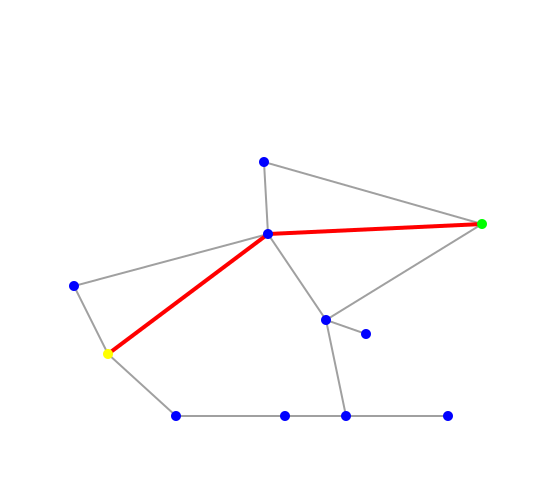

In [13]:
use plotters::prelude::*;
use std::cmp::Reverse;
use std::collections::{BinaryHeap, HashMap};

// Coordonnées (longitude, latitude) normalisées — identiques au jumeau Python.
let pos: Vec<(&str, f64, f64)> = vec![
    ("Paris", 2.35, 6.3),
    ("Lyon", 3.2, 4.5),
    ("Marseille", 3.5, 2.5),
    ("Lille", 2.3, 7.8),
    ("Strasbourg", 5.5, 6.5),
    ("Bordeaux", 0.0, 3.8),
    ("Toulouse", 1.0, 2.5),
    ("Montpellier", 2.6, 2.5),
    ("Nantes", -0.5, 5.2),
    ("Nice", 5.0, 2.5),
    ("Grenoble", 3.8, 4.2),
];
{
    // Adjacence + Dijkstra maison (BinaryHeap) pour recalculer l'itinéraire.
    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    let mut dist: HashMap<&str, u32> = HashMap::new();
    let mut tas: BinaryHeap<Reverse<(u32, &str)>> = BinaryHeap::new();
    dist.insert("Bordeaux", 0);
    tas.push(Reverse((0, "Bordeaux")));
    while let Some(Reverse((d, v))) = tas.pop() {
        if d > dist[v] { continue; }
        for &(w, poids) in &adj[v] {
            if d + poids < *dist.get(w).unwrap_or(&u32::MAX) {
                dist.insert(w, d + poids);
                tas.push(Reverse((d + poids, w)));
            }
        }
    }
    let mut chemin: Vec<&str> = vec!["Strasbourg"];
    let mut courant = "Strasbourg";
    while courant != "Bordeaux" {
        for &(w, poids) in &adj[courant] {
            if dist[w] + poids == dist[courant] {
                chemin.push(w);
                courant = w;
                break;
            }
        }
    }
    chemin.reverse();
    println!("Itineraire optimal trace en rouge : {} ({} km)", chemin.join(" -> "), dist["Strasbourg"]);

    // Projection (longitude, latitude) -> pixels. lon dans [-1, 6], lat dans [2, 8].
    let to_px = |lon: f64, lat: f64| -> (i32, i32) {
        let x = 40.0 + (lon + 1.0) * 68.0;
        let y = 440.0 - (lat - 2.0) * 48.0;
        (x.round() as i32, y.round() as i32)
    };
    let xy = |nom: &str| -> (f64, f64) {
        let &(_, lon, lat) = pos.iter().find(|p| p.0 == nom).unwrap();
        (lon, lat)
    };

    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (560, 480)).into_drawing_area();
        root.fill(&WHITE)?;
        // Arêtes en gris
        for (a, b, _) in &france_edges {
            let (x1, y1) = xy(a);
            let (x2, y2) = xy(b);
            let (p1, p2) = (to_px(x1, y1), to_px(x2, y2));
            root.draw(&PathElement::new(vec![p1, p2], ShapeStyle::from(&RGBColor(160, 160, 160)).stroke_width(2)))?;
        }
        // Itineraire optimal en rouge épais
        let points: Vec<(i32, i32)> = chemin.iter().map(|v| { let (lo, la) = xy(v); to_px(lo, la) }).collect();
        root.draw(&PathElement::new(points, ShapeStyle::from(&RED).stroke_width(4)))?;
        // Villes : jaune = départ, vert = arrivée, bleu = autres
        for &(nom, lon, lat) in &pos {
            let p = to_px(lon, lat);
            let style = if nom == "Bordeaux" { ShapeStyle::from(&YELLOW).filled() }
                else if nom == "Strasbourg" { ShapeStyle::from(&GREEN).filled() }
                else { ShapeStyle::from(&BLUE).filled() };
            root.draw(&Circle::new(p, 5, style))?;
        }
        root.present()?;
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
};

### Lecture de la figure

L'itinéraire rouge remonte du Sud-Ouest vers **Paris** puis file à l'Est vers Strasbourg : 2 étapes, 1075 km. Le chemin du sud (gris, via Toulouse-Montpellier-Marseille-Lyon) dessine un arc de cercle complet autour du Massif central — visiblement plus long. La carte rend aussi la centralité de Lyon lisible à l'œil : la ville est au croisement des axes Nord-Sud (Paris-Marseille) et Est-Ouest (Strasbourg-Grenoble), tandis que Paris, extrême ouest-nord du réseau, ne sert que les flux qui y vont vraiment.

## 5. Exemples guidés : missionnaires-cannibales et labyrinthe

### Les missionnaires et les cannibales

Trois missionnaires et trois cannibales doivent traverser une rivière dans une barque à deux places. Si, sur une rive, les cannibales sont strictement plus nombreux que les missionnaires, le drame se produit. L'état est le triplet `(missionnaires à gauche, cannibales à gauche, côté du bateau)` ; un **état invalide** n'est jamais visité — le filtrage se fait dans la génération des actions.

In [14]:
{
    // (S, s0, A, T, G) pour les missionnaires et les cannibales.
    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct RiveState {
        m_g: u32,     // missionnaires sur la rive gauche
        c_g: u32,     // cannibales sur la rive gauche
        bateau: char, // 'G' ou 'D'
    }

    fn rive_valide(m: u32, c: u32) -> bool { m == 0 || m >= c }

    fn etat_valide(s: &RiveState) -> bool {
        rive_valide(s.m_g, s.c_g) && rive_valide(3 - s.m_g, 3 - s.c_g)
    }

    fn transition_me(s: &RiveState, m: u32, c: u32) -> RiveState {
        let mut n = s.clone();
        if s.bateau == 'G' {
            n.m_g -= m; n.c_g -= c; n.bateau = 'D';
        } else {
            n.m_g += m; n.c_g += c; n.bateau = 'G';
        }
        n
    }

    // Actions : (m, c) passagers embarqués, 1 <= m + c <= 2. Seules les actions
    // dont le chargement est possible ET l'état cible valide sont proposées.
    fn actions_possibles(s: &RiveState) -> Vec<(u32, u32)> {
        let mut res = Vec::new();
        for m in 0..=2u32 {
            for c in 0..=2u32 {
                if 1 <= m + c && m + c <= 2 {
                    let chargeable = if s.bateau == 'G' { m <= s.m_g && c <= s.c_g }
                                     else { m <= 3 - s.m_g && c <= 3 - s.c_g };
                    if chargeable && etat_valide(&transition_me(s, m, c)) {
                        res.push((m, c));
                    }
                }
            }
        }
        res
    }

    // Taille de l'espace d'états : les triplets valides parmi 4 x 4 x 2
    let mut compteur = 0;
    for m in 0..=3u32 { for c in 0..=3u32 { for b in ['G', 'D'] {
        if etat_valide(&RiveState { m_g: m, c_g: c, bateau: b }) { compteur += 1; }
    }}}
    println!("Etats valides : {} sur 32 triplets possibles", compteur);

    let initial = RiveState { m_g: 3, c_g: 3, bateau: 'G' };
    println!("Actions depuis l'etat initial : {:?}", actions_possibles(&initial));
    println!();

    // BFS : file FIFO + ensemble des états vus
    use std::collections::{HashSet, VecDeque};
    let mut vus: HashSet<RiveState> = HashSet::new();
    let mut file: VecDeque<(RiveState, Vec<(u32, u32)>)> = VecDeque::new();
    vus.insert(initial.clone());
    file.push_back((initial.clone(), Vec::new()));
    let mut solution: Option<Vec<(u32, u32)>> = None;
    while let Some((etat, chemin)) = file.pop_front() {
        if etat.m_g == 0 && etat.c_g == 0 {
            solution = Some(chemin);
            break;
        }
        for (m, c) in actions_possibles(&etat) {
            let suivant = transition_me(&etat, m, c);
            if vus.insert(suivant.clone()) {
                let mut ch = chemin.clone();
                ch.push((m, c));
                file.push_back((suivant, ch));
            }
        }
    }

    fn affiche_rive(m: u32, c: u32) -> String { format!("{}M {}C", m, c) }

    println!("{:<6}{:<14}{:<12}{:<12}{}", "Etape", "Action (M,C)", "Rive gauche", "Rive droite", "Bateau");
    let mut etat = initial;
    println!("{:<6}{:<14}{:<12}{:<12}{}", "init", "-", affiche_rive(etat.m_g, etat.c_g), affiche_rive(3 - etat.m_g, 3 - etat.c_g), etat.bateau);
    match solution {
        Some(chemin) => {
            for (i, &(m, c)) in chemin.iter().enumerate() {
                etat = transition_me(&etat, m, c);
                let sens = if etat.bateau == 'D' { "->" } else { "<-" };
                println!("{:<6}{:<14}{:<12}{:<12}{}", i + 1, format!("({}, {}) {}", m, c, sens),
                    affiche_rive(etat.m_g, etat.c_g), affiche_rive(3 - etat.m_g, 3 - etat.c_g), etat.bateau);
            }
            println!();
            println!("Solution en {} traversees.", chemin.len());
        }
        None => println!("Aucune solution."),
    }
};

Etats valides : 20 sur 32 triplets possibles


Actions depuis l'etat initial : [(0, 1), (0, 2), (1, 1)]


Etape Action (M,C)  Rive gauche Rive droite Bateau


init  -             3M 3C       0M 0C       G


1     (0, 2) ->     3M 1C       0M 2C       D


2     (0, 1) <-     3M 2C       0M 1C       G


... (6 outputs left out)

9     (0, 2) ->     0M 1C       3M 2C       D


10    (0, 1) <-     0M 2C       3M 1C       G


11    (0, 2) ->     0M 0C       3M 3C       D


Solution en 11 traversees.


### Lecture du résultat

L'espace brut compte 32 triplets (4 x 4 x 2), mais seuls **20 états sont valides** : les 12 autres mettent des missionnaires en danger sur une rive. Depuis l'état initial, seules trois actions survivent au filtre — embarquer **(0,1)**, **(0,2)** ou **(1,1)** : embarquer des missionnaires sans cannibales les laisserait en infériorité à gauche. La solution compte **11 traversées** : la barque fait systématiquement l'aller-retour en emportant au maximum deux personnes, et un seul état (voyage solitaire) ramène le bateau. Le BFS ne visite que des états valides — le filtre dans `actions_possibles` remplace le post-filtrage du jumeau Python.

### Le labyrinthe

Dernier exemple guidé : un labyrinthe en grille ASCII, où `S` marque le départ, `E` la sortie et `#` un mur. L'état est le couple `(ligne, colonne)` ; les actions sont les quatre directions. Trois cas : une sortie voisine du départ, une sortie inatteignable, et la grille de l'énoncé.

In [15]:
{
    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct Pos { l: i32, c: i32 }

    struct MazeProblem {
        grille: Vec<Vec<char>>,
        depart: Pos,
        sortie: Pos,
    }

    const DIRECTIONS: [(&str, i32, i32); 4] = [
        ("Haut", -1, 0),
        ("Bas", 1, 0),
        ("Gauche", 0, -1),
        ("Droite", 0, 1),
    ];

    impl MazeProblem {
        fn nouvelle(grille: &[&str]) -> Option<MazeProblem> {
            let g: Vec<Vec<char>> = grille.iter().map(|l| l.chars().collect()).collect();
            let (mut depart, mut sortie) = (None, None);
            for (l, ligne) in g.iter().enumerate() {
                for (c, &ch) in ligne.iter().enumerate() {
                    if ch == 'S' { depart = Some(Pos { l: l as i32, c: c as i32 }); }
                    if ch == 'E' { sortie = Some(Pos { l: l as i32, c: c as i32 }); }
                }
            }
            match (depart, sortie) {
                (Some(d), Some(s)) => Some(MazeProblem { grille: g, depart: d, sortie: s }),
                _ => None,
            }
        }
        fn franchissable(&self, l: i32, c: i32) -> bool {
            l >= 0 && c >= 0
                && (l as usize) < self.grille.len()
                && (c as usize) < self.grille[0].len()
                && self.grille[l as usize][c as usize] != '#'
        }
        fn actions_de(&self, p: &Pos) -> Vec<&'static str> {
            let mut res = Vec::new();
            for (nom, dl, dc) in DIRECTIONS {
                if self.franchissable(p.l + dl, p.c + dc) { res.push(nom); }
            }
            res
        }
        fn cases_libres(&self) -> usize {
            self.grille.iter().map(|l| l.iter().filter(|&&ch| ch != '#').count()).sum()
        }
    }

    fn bouger(p: &Pos, action: &str) -> Pos {
        for (nom, dl, dc) in DIRECTIONS {
            if nom == action {
                return Pos { l: p.l + dl, c: p.c + dc };
            }
        }
        p.clone()
    }

    // BFS : plus court chemin du départ a la sortie, en nombre d'actions
    fn bfs_chemin(m: &MazeProblem) -> Option<Vec<&'static str>> {
        use std::collections::{HashSet, VecDeque};
        let mut vus: HashSet<Pos> = HashSet::new();
        let mut file: VecDeque<(Pos, Vec<&'static str>)> = VecDeque::new();
        vus.insert(m.depart.clone());
        file.push_back((m.depart.clone(), Vec::new()));
        while let Some((p, chemin)) = file.pop_front() {
            if p == m.sortie { return Some(chemin); }
            for a in m.actions_de(&p) {
                let suivant = bouger(&p, a);
                if vus.insert(suivant.clone()) {
                    let mut ch = chemin.clone();
                    ch.push(a);
                    file.push_back((suivant, ch));
                }
            }
        }
        None
    }

    fn analyser(titre: &str, grille: &[&str]) {
        println!("=== {} ===", titre);
        match MazeProblem::nouvelle(grille) {
            Some(m) => {
                println!("Labyrinthe {}x{} | depart ({}, {}) | sortie ({}, {}) | cases accessibles : {}",
                    m.grille.len(), m.grille[0].len(),
                    m.depart.l, m.depart.c, m.sortie.l, m.sortie.c, m.cases_libres());
                println!("Actions depuis le depart : {:?}", m.actions_de(&m.depart));
                match bfs_chemin(&m) {
                    Some(chemin) => println!("Solution trouvee en {} etapes : {}", chemin.len(), chemin.join(" -> ")),
                    None => println!("Aucune solution : la sortie est inatteignable."),
                }
            }
            None => println!("Grille invalide : il faut exactement un 'S' et un 'E'."),
        }
        println!();
    }

    analyser("Cas limite : sortie voisine du depart", &["SE"]);
    analyser("Cas limite : sortie inatteignable", &["S#E"]);
    analyser("Cas nominal : grille de l'enonce", &["S.#....", ".#.#.#.", ".#...#.", ".###.#.", ".....#E"]);
};

=== Cas limite : sortie voisine du depart ===


Labyrinthe 1x2 | depart (0, 0) | sortie (0, 1) | cases accessibles : 2


Actions depuis le depart : ["Droite"]


Solution trouvee en 1 etapes : Droite


=== Cas limite : sortie inatteignable ===


Labyrinthe 1x3 | depart (0, 0) | sortie (0, 2) | cases accessibles : 2


... (2 outputs left out)

=== Cas nominal : grille de l'enonce ===


Labyrinthe 5x7 | depart (0, 0) | sortie (4, 6) | cases accessibles : 24


Actions depuis le depart : ["Bas", "Droite"]


Solution trouvee en 18 etapes : Bas -> Bas -> Bas -> Bas -> Droite -> Droite -> Droite -> Droite -> Haut -> Haut -> Haut -> Haut -> Droite -> Droite -> Bas -> Bas -> Bas -> Bas


### Lecture du résultat

Les deux cas limites calibrent le solveur : `SE` (sortie voisine) se résout en **1 étape** (`Droite`), et `S#E` (mur entre les deux) n'a **aucune solution** — le BFS épuise les 2 cases accessibles sans atteindre la sortie. La grille 5x7 de l'énoncé offre 24 cases accessibles et une solution en **18 étapes** : 4 fois `Bas`, 4 fois `Droite`, 4 fois `Haut`, 2 fois `Droite`, puis 4 fois `Bas`. Remarquez la séquence `Haut` au milieu du chemin : le plus court chemin n'est pas monotone — il faut revenir sur ses pas pour contourner le mur central, et le chemin repasse par des cases déjà traversées. C'est normal : le critère est le nombre d'actions, pas le nombre de cases distinctes.

## 6. Exercices

Trois exercices, du diagnostic (parité du taquin) à la modélisation complète (cruches d'eau). Chaque stub s'exécute sans erreur : le notebook reste valide même non complété.

### Exercice 4 — La parité du taquin

**Objectif** : écrire `nombre_inversions` (compter les paires mal ordonnées en ignorant la case vide) puis `est_soluble` (sur grille de largeur impaire, un état est atteignable depuis le but si et seulement si le nombre d'inversions est pair), et vérifier sur l'état initial du carnet.

**Indice** : pour `nombre_inversions`, un double `for` sur les indices `i < j` avec `etat[i] > etat[j]` et `etat[j] != 0` suffit. Pour `est_soluble`, largeur 3 = impaire : la parité seule décide.

In [16]:
// EXERCICE 4 : parité du taquin
// TODO étudiant :
// 1. Compléter nombre_inversions (double boucle sur les paires i < j)
// 2. Compléter est_soluble (largeur impaire : atteignable si et seulement si inversions pair)
// 3. Vérifier sur l'état initial [7, 2, 4, 5, 0, 6, 8, 3, 1]
{
    // Indice : ignorer la case vide (0) dans le comptage des inversions.
    fn nombre_inversions(etat: &[u8; 9]) -> usize {
        // Étape 1 : pour chaque paire (i, j) avec i < j, compter si etat[i] > etat[j] > 0
        let _ = etat;
        0
    }

    fn est_soluble(etat: &[u8; 9]) -> bool {
        // Étape 2 : grille de largeur 3 (impaire) -> inversions pair si et seulement si soluble
        let _ = etat;
        false
    }

    let exemple: [u8; 9] = [2, 1, 3, 4, 5, 6, 7, 8, 0];
    println!("Exercice a completer : nombre_inversions([2, 1, 3, ...]) = {}", nombre_inversions(&exemple));
    println!("Exercice a completer : determiner est_soluble([7, 2, 4, 5, 0, 6, 8, 3, 1])");
};

Exercice a completer : nombre_inversions([2, 1, 3, ...]) = 0


Exercice a completer : determiner est_soluble([7, 2, 4, 5, 0, 6, 8, 3, 1])


### Exercice 5 — Le labyrinthe avec clé

**Objectif** : étendre le labyrinthe avec une clé `K` à ramasser et une porte `D` qui ne s'ouvre qu'avec la clé. L'état devient le triplet `(ligne, colonne, a_la_cle)`.

**Indice** : la grille de test est `K.S.. / ####. / E.D..` — la clé est au nord-ouest, la porte ferme le couloir sud vers `E`. L'espace d'états compte (cases libres) x 2 états de clé. Question bonus : pourquoi le chemin optimal repasse-t-il par des cases déjà traversées ?

In [17]:
// EXERCICE 5 : labyrinthe avec clé 'K' et porte 'D'
// TODO étudiant :
// 1. Compléter taille_espace_cle (cases hors murs x 2, avec ou sans la clé)
// 2. Compléter resoudre_avec_cle (BFS sur l'état (ligne, colonne, a_la_cle))
{
    fn taille_espace_cle(grille: &[&str]) -> usize {
        // Étape 1 : compter les cases != '#' et multiplier par 2 (clé possédée ou non)
        let _ = grille;
        0
    }

    fn resoudre_avec_cle(grille: &[&str]) -> Vec<String> {
        // Étape 2 : BFS depuis (ligne de 'S', colonne de 'S', false) ;
        // Indice : marcher sur 'K' passe a_la_cle à true ; 'D' est franchissable
        // seulement si a_la_cle ; le but est la case 'E'.
        let _ = grille;
        Vec::new()
    }

    let key_grid = ["K.S..", "####.", "E.D.."];
    println!("Exercice a completer : {} etats possibles", taille_espace_cle(&key_grid));
    println!("Exercice a completer : {} etapes", resoudre_avec_cle(&key_grid).len());
};

Exercice a completer : 0 etats possibles


Exercice a completer : 0 etapes


### Exercice 6 — Les cruches d'eau

**Objectif** : modéliser deux cruches (capacités 3 L et 5 L) et mesurer exactement 4 L. Les actions sont remplir une cruche, la vider, ou transvaser jusqu'à débordement/épuisement ; le but est qu'une cruche contienne exactement le volume cible.

**Indice** : l'état est le couple `(contenu_a, contenu_b)` — l'espace compte `(3+1) x (5+1) = 24` états au plus. Question bonus : avec des cruches de 2 L et 4 L, pourquoi 3 L est-il inatteignable ? (pensez aux multiples de 2).

In [18]:
// EXERCICE 6 : les cruches d'eau
// TODO etudiant :
// 1. Completer taille_espace_cruches ((cap_a + 1) * (cap_b + 1))
// 2. Completer bfs_cruches (BFS depuis (0, 0) ; but : une cruche == cible)
{
    fn taille_espace_cruches(cap_a: u32, cap_b: u32) -> usize {
        // Etape 1 : chaque cruche contient de 0 a sa capacite
        let _ = (cap_a, cap_b);
        0
    }

    fn bfs_cruches(cap_a: u32, cap_b: u32, cible: u32) -> usize {
        // Etape 2 : actions = RemplirA, RemplirB, ViderA, ViderB, VerserAB, VerserBA
        // Indice : le transvasement s'arrete au debordement du recepteur ou a
        // l'epuisement du donneur ; le but est contenu_a == cible ou contenu_b == cible.
        let _ = (cap_a, cap_b, cible);
        0
    }

    println!("Exercice a completer : cruches 3/5 -> {} etats possibles", taille_espace_cruches(3, 5));
    println!("Exercice a completer : BFS vers 4 L : {} actions", bfs_cruches(3, 5, 4));
};

Exercice a completer : cruches 3/5 -> 0 etats possibles


Exercice a completer : BFS vers 4 L : 0 actions


## À retenir

- **Le trait remplace la classe abstraite** : le 5-uplet (S, s0, A, T, G) devient `trait SearchProblem` avec un type associé `State` — chaque problème choisit sa représentation d'état (struct, tableau, tuple).
- **Le BFS tient en dix lignes de std** : `VecDeque` (file FIFO) + `HashSet` (états vus) ; l'insertion dans l'ensemble sert de garde anti-doublon.
- **`petgraph` est l'organe natif des graphes** : `Graph` + `petgraph::algo::dijkstra` remplacent l'implémentation maison ; la betweenness, absente de la crate, reste une copie pédagogique déclarée (Brandes), recoupée contre `networkx`.
- **`u128` pour les factorielles** : 21! déborde `u64`, et un débordement Rust panique en debug — choisir le type AVANT d'écrire la boucle.
- **evcxr : `:dep` en tête, cellules autonomes** : les items (traits, fonctions) ne persistent pas fiablement ; chaque cellule de ce carnet est un bloc `{ ... };` autonome, seules les données simples (`france_edges`) persistent.
- **La vérification croisée** : chemin manuel vs Dijkstra (1075 km des deux côtés), Brandes vs networkx (Lyon/Marseille 0.422) — deux voies d'accès indépendantes au même chiffre.

## Vérifiez votre compréhension

1. **Pourquoi chaque cellule de ce carnet redéfinit-elle le trait `SearchProblem` dans son propre bloc, au lieu de le définir une fois pour toutes ?**

   <details>
   <summary>Réponse</summary>

   Le kernel evcxr compile cellule par cellule et ne persiste pas fiablement les items (traits, fonctions, types) au-delà de leur cellule de définition — seules les variables top-level de types simples survivent (comme `france_edges`). Enclos dans un bloc `{ ... };`, chaque cellule est autonome : elle recompile et s'exécute seule, ce qui rend aussi le carnet robuste à la ré-exécution partielle.
   </details>

2. **Pourquoi la cellule factorielle utilise-t-elle `u128` et que se passerait-il avec `u64` sur le 24-puzzle ?**

   <details>
   <summary>Réponse</summary>

   `20!` (environ `2.43e18`) est le dernier factoriel représentable en `u64` (borne `2^64 - 1` environ `1.8e19`) ; `21!` déborde. En Rust, un débordement arithmétique en compilation debug **panique** avec `attempt to multiply with overflow` au lieu de s'enrouler en silence : la cellule s'arrêterait avec une erreur au lieu d'afficher un résultat faux — comportement plus sûr, mais qu'il faut anticiper en choisissant `u128` (borne environ `3.4e38`, où `25!` tient largement).
   </details>

3. **La centralité classe Lyon et Marseille (0.422) devant Paris (0.267), alors que Paris a plus de routes. Pourquoi ?**

   <details>
   <summary>Réponse</summary>

   La betweenness compte les **plus courts chemins qui traversent** un sommet, pas ses arêtes. Lyon est la charnière des flux nord-sud (Paris-Marseille) et est-ouest (Strasbourg-Grenoble) : presque tout transit sud-est vers nord y passe. Paris, extrémité nord-ouest du réseau, n'est sur le chemin que des paires dont il est une extrémité ou un relais optimal (comme Bordeaux-Strasbourg) — ses 5 arêtes en font un hub de degré élevé, pas un point de passage.
   </details>

## Pour aller plus loin

- [Search-01 Python](Search-01-StateSpace.ipynb) — la théorie complète : formalisation, exemples fondateurs, pièges classiques.
- [Search-01 C#](Search-01-StateSpace-CSharp.ipynb) — le même problème dans le jumeau .NET (sur un graphe de France différent : 13 villes, 41 arcs).
- [Search-02 Uninformed](Search-02-Uninformed.ipynb) — la suite de la série : BFS, DFS et Dijkstra en tant qu'algorithmes génériques non informés.
- [La crate petgraph (docs.rs)](https://docs.rs/petgraph) — la documentation de l'organe : `Graph`, `algo::dijkstra`, `algo::astar`, et les parcours.
- Brandes (2001), *A Faster Algorithm for Betweenness Centrality* — l'algorithme de la copie pédagogique.